# Reference and target samples

Compare two mixtures using **`weight_kFact`** as the event weight:

| Sample | Selection |
|---|---|
| Reference | `Type` is `S` or `EWSBI10` |
| Target | `Type` is `SBI` or `qqZZ` |

Each variable has **two separate plots: weighted yields first, then a normalized shape**. Signed event weights and the relative contributions of the component processes are preserved.

| Variable | Range | Bin width | Number of bins |
|---|---|---|---|
| `NN_disc_New` | −1 to 1 | 0.05 | 40 |
| `m4l_fsr` | 150 to 2000 GeV | 50 GeV | 37 |

Run all cells on a CPU runtime. The four figures are displayed here and saved as PNG/PDF under the project folder in Drive.

## Setup

Colab loads `utils.py` from this repository. That file contains the HDF5 column reader and plot styling; selections, binning, and weighted histograms are below.

In [1]:
%pip -q install mplhep tables

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.7/93.7 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 39.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 36.2 MB/s eta 0:00:00


In [2]:

from pathlib import Path
from urllib.request import urlretrieve
import importlib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import mplhep as hep
from IPython.display import display

try:
    from google.colab import drive
except ImportError:
    import utils as offshell_utils
else:
    drive.mount("/content/drive")
    urlretrieve(
        "https://raw.githubusercontent.com/rafaellopesdesa/offshell_reweighting/main/utils.py",
        "/content/offshell_utils.py",
    )
    import offshell_utils

# Reload the downloaded helper even if this Colab runtime was used before.
importlib.invalidate_caches()
importlib.reload(offshell_utils)
load_columns = offshell_utils.load_columns
plot_comparison = offshell_utils.plot_comparison
hep.style.use("ATLAS")
print(f"Matplotlib {matplotlib.__version__}; mplhep {hep.__version__}")

Mounted at /content/drive
Matplotlib 3.10.0; mplhep 1.3.3


In [3]:
PROJECT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/HZZ_OffShell")
DATA_PATH = PROJECT_DIR / "dataset_wDR_mean_origIndex.h5"
PLOT_DIR = PROJECT_DIR / "plots" / "01_reference_sample"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

NN_BINS = np.linspace(-1.0, 1.0, 41)          # 40 bins of width 0.05.
M4L_BINS = np.arange(150.0, 2000.0 + 50, 50)  # 37 bins of width 50 GeV.

## Load four columns and select the samples

The input contains a pandas fixed-format group named `dataset`. Reading only these columns keeps memory use smaller than loading the whole 66-column DataFrame. `Type` is stored together with `subType` in an object block, which must be read together once.

Rows with nonfinite values in either plotted variable or the weight are excluded from both plots and counted below. No other event cuts or process-dependent rescaling are applied.

In [4]:
data = load_columns(DATA_PATH, ["Type", "weight_kFact", "NN_disc_New", "m4l_fsr"])
event_type = data["Type"]
weights = np.asarray(data["weight_kFact"], dtype=np.float64)

reference = np.isin(event_type, ["S", "EWSBI10"])
target = np.isin(event_type, ["SBI", "qqZZ"])

finite = (np.isfinite(weights) & np.isfinite(data["NN_disc_New"])
          & np.isfinite(data["m4l_fsr"]))
print(f"Excluded nonfinite rows: reference={np.count_nonzero(reference & ~finite):,}, "
      f"target={np.count_nonzero(target & ~finite):,}")
reference &= finite
target &= finite

summary = []
for name, mask in [("Reference", reference), ("Target", target)]:
    summary.append({"sample": name, "events": int(mask.sum()),
                    "sum_weights": weights[mask].sum(),
                    "negative_weights": int(np.count_nonzero(weights[mask] < 0))})
display(pd.DataFrame(summary).set_index("sample"))

Excluded nonfinite rows: reference=0, target=0


,events,sum_weights,negative_weights
sample,,,
Reference,3110759,91.773434,1333
Target,4317574,2010.603823,488283


## Yields inside and outside the plotting ranges

The yield plots show the **sum of `weight_kFact` in each bin**, with no normalization or additional luminosity factor. Values outside the requested ranges are excluded from the histograms and reported separately below; they are not folded into edge bins. The final right edge is included, matching `np.histogram`.

The normalized plots divide each combined mixture by its **in-range signed weight** and the bin width. Individual processes are never normalized separately.

In [5]:
if not reference.any() or not target.any():
    raise ValueError("Both reference and target selections must contain events.")

range_summary = []
for variable, bins in [("NN_disc_New", NN_BINS), ("m4l_fsr", M4L_BINS)]:
    for name, mask in [("Reference", reference), ("Target", target)]:
        x, w = data[variable][mask], weights[mask]
        below = x < bins[0]
        above = x > bins[-1]
        inside = ~(below | above)
        range_summary.append({
            "variable": variable, "sample": name,
            "yield_in_range": w[inside].sum(),
            "yield_below_range": w[below].sum(),
            "yield_above_range": w[above].sum(),
        })
display(pd.DataFrame(range_summary).set_index(["variable", "sample"]))

yield_in_range  yield_below_range  yield_above_range
variable    sample                                                         
NN_disc_New Reference       90.832493                0.0           0.940940
            Target        2008.875271                0.0           1.728552
m4l_fsr     Reference       91.773434                0.0           0.000000
            Target        2010.603823                0.0           0.000000

## `NN_disc_New`: yields and normalized shape

Range `[-1, 1]`, with 0.05-wide bins. The first figure shows yields; the second shows the normalized shape.

ImportError: cannot import name 'FontPath' from 'matplotlib.font_manager' (/usr/local/lib/python3.13/dist-packages/matplotlib/font_manager.py)

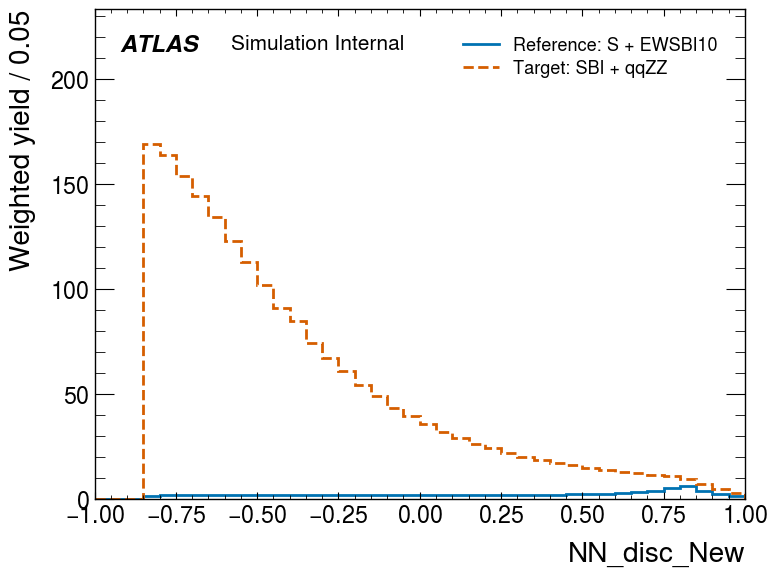

In [6]:
x = data["NN_disc_New"]
h_reference, _ = np.histogram(x[reference], bins=NN_BINS, weights=weights[reference])
h_target, _ = np.histogram(x[target], bins=NN_BINS, weights=weights[target])

for mode in ("yields", "normalized"):
    h_ref, h_tgt = h_reference.copy(), h_target.copy()
    ylabel = "Weighted yield / 0.05"
    if mode == "normalized":
        if h_ref.sum() == 0 or h_tgt.sum() == 0:
            print("Skipping normalized NN_disc_New: a sample has zero in-range weight.")
            continue
        h_ref = h_ref / (h_ref.sum() * np.diff(NN_BINS))
        h_tgt = h_tgt / (h_tgt.sum() * np.diff(NN_BINS))
        ylabel = "Normalized density"
    fig, ax = plot_comparison(h_ref, h_tgt, NN_BINS, xlabel="NN_disc_New", ylabel=ylabel)
    for extension in ("png", "pdf"):
        fig.savefig(PLOT_DIR / f"NN_disc_New_{mode}.{extension}", dpi=180, bbox_inches="tight")
    plt.show()

## `m4l_fsr`: yields and normalized shape

Range `[150, 2000]` GeV, with 50 GeV-wide bins. The first figure shows yields; the second shows the normalized shape.

In [ ]:
x = data["m4l_fsr"]
h_reference, _ = np.histogram(x[reference], bins=M4L_BINS, weights=weights[reference])
h_target, _ = np.histogram(x[target], bins=M4L_BINS, weights=weights[target])

for mode in ("yields", "normalized"):
    h_ref, h_tgt = h_reference.copy(), h_target.copy()
    ylabel = "Weighted yield / 50 GeV"
    if mode == "normalized":
        if h_ref.sum() == 0 or h_tgt.sum() == 0:
            print("Skipping normalized m4l_fsr: a sample has zero in-range weight.")
            continue
        h_ref = h_ref / (h_ref.sum() * np.diff(M4L_BINS))
        h_tgt = h_tgt / (h_tgt.sum() * np.diff(M4L_BINS))
        ylabel = r"Normalized density [GeV$^{-1}$]"
    fig, ax = plot_comparison(
        h_ref, h_tgt, M4L_BINS, xlabel=r"$m_{4\ell}^{\mathrm{FSR}}$ [GeV]", ylabel=ylabel,
    )
    for extension in ("png", "pdf"):
        fig.savefig(PLOT_DIR / f"m4l_fsr_{mode}.{extension}", dpi=180, bbox_inches="tight")
    plt.show()
print(f"Figures saved to {PLOT_DIR}")